# Next Step Validation для user similarity

Этот ноутбук переводит оценку similarity из чисто геометрической плоскости в более прикладную валидацию:

- по сегментам активности
- по semantic overlap соседей
- по bias на activity scale
- по temporal holdout
- по новым наборам признаков
- по качественному аудиту соседей

Все пояснения и выводы даны на русском языке.

In [1]:
import gc
import inspect
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = {
    "random_seed": 42,
    "feature_sample_size": 6000,
    "segment_sample_size": 1200,
    "neighbors_k": 5,
    "holdout_ratio": 0.2,
    "recommendation_top_k": [5, 10],
    "min_transactions_threshold": 5,
    "merchant_frequency_cutoff": 10,
    "semantic_user_limit": 2500,
    "holdout_user_limit": 1200,
    "audit_user_count": 30,
    "tx_chunksize": 200000,
    "weighted_batch_size": 64,
}

RANDOM_STATE = CONFIG["random_seed"]
rng = np.random.default_rng(RANDOM_STATE)
FEATURE_PATH = Path("artifacts/user_features_data1.csv")
TX_PARQUET_PATH = Path("artifacts/intermediate/tx_enriched_data1.parquet")
TX_CSV_FALLBACK_PATH = Path("trans600.csv")
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
ID_COL = "party_rk"
DATE_COLS = ["first_txn_dttm", "last_txn_dttm"]
KEY_SCALE_COLS = ["txn_cnt", "active_days_cnt", "unique_category_cnt", "unique_mcc_cnt", "unique_merchant_cnt"]

## 1. Конфигурация и загрузка данных

Сначала фиксируем явную конфигурацию sampling и загружаем базовый feature-датасет. Транзакционный датасет будем читать выборочно по пользователям, чтобы не раздувать память без необходимости.

In [2]:
class Log1pTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns or []

    def fit(self, X, y=None):
        self.columns_ = [c for c in self.columns if c in X.columns]
        return self

    def transform(self, X):
        X = X.copy()
        if self.columns_:
            X.loc[:, self.columns_] = np.log1p(np.clip(X.loc[:, self.columns_].astype("float32"), a_min=0, a_max=None))
        return X


def make_onehot():
    params = inspect.signature(OneHotEncoder).parameters
    if "sparse_output" in params:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return OneHotEncoder(handle_unknown="ignore", sparse=False)


def infer_feature_dtypes(path, sample_rows=3000):
    sample = pd.read_csv(path, nrows=sample_rows)
    cat_cols = [c for c in ["dominant_daypart", "dominant_weekday"] if c in sample.columns]
    num_cols = [c for c in sample.columns if c not in [ID_COL, *DATE_COLS, *cat_cols]]
    dtype_map = {c: "float32" for c in num_cols}
    dtype_map[ID_COL] = "object"
    for c in cat_cols:
        dtype_map[c] = "object"
    parse_dates = [c for c in DATE_COLS if c in sample.columns]
    return dtype_map, parse_dates, cat_cols


def load_feature_data(path):
    dtype_map, parse_dates, cat_cols = infer_feature_dtypes(path)
    df = pd.read_csv(path, dtype=dtype_map, parse_dates=parse_dates, low_memory=False)
    for c in cat_cols:
        if c in df.columns:
            df[c] = df[c].astype("category")
    return df


def add_datetime_features(df):
    out = df.copy()
    present = [c for c in DATE_COLS if c in out.columns]
    if present:
        ref = max(out[c].max() for c in present)
        if "first_txn_dttm" in out.columns:
            out["days_since_first_txn"] = (ref - out["first_txn_dttm"]).dt.days.astype("float32")
        if "last_txn_dttm" in out.columns:
            out["days_since_last_txn"] = (ref - out["last_txn_dttm"]).dt.days.astype("float32")
        if set(["first_txn_dttm", "last_txn_dttm"]).issubset(out.columns):
            out["tenure_days"] = (out["last_txn_dttm"] - out["first_txn_dttm"]).dt.days.astype("float32")
    return out


def activity_segment(series):
    return np.select(
        [series <= 2, series.between(3, 5), series.between(6, 20), series > 20],
        ["cold", "low", "mid", "high"],
        default="unknown",
    )


def detect_log_cols(df):
    cols = []
    for c in df.columns:
        if str(df[c].dtype) == "category":
            continue
        if c.startswith("share_") or c.endswith("_share") or "entropy" in c:
            continue
        if c.endswith("_cnt") or c.startswith("unique_") or c.startswith("days_since_") or c in {"tenure_days", "max_txn_in_one_day", "median_txn_per_active_day"}:
            cols.append(c)
    return sorted(set(cols))


def robust_matrix(df):
    cat_cols = [c for c in df.columns if str(df[c].dtype) == "category" or df[c].dtype == "object"]
    num_cols = [c for c in df.columns if c not in cat_cols]
    log_cols = [c for c in detect_log_cols(df) if c in num_cols]
    pipe = Pipeline([
        ("log1p", Log1pTransformer(log_cols)),
        ("ct", ColumnTransformer([
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]), num_cols),
            ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", make_onehot())]), cat_cols),
        ], remainder="drop", sparse_threshold=0.0)),
    ])
    X = np.asarray(pipe.fit_transform(df), dtype=np.float32)
    return X, pipe


def overlapping_stability(X, metric, user_ids, seed=42):
    if len(user_ids) < 50:
        return np.nan
    local_rng = np.random.default_rng(seed)
    idx = np.arange(len(user_ids))
    size = max(20, int(0.8 * len(idx)))
    a = np.sort(local_rng.choice(idx, size=size, replace=False))
    b = np.sort(local_rng.choice(idx, size=size, replace=False))
    _, ia = knn_run(X[a], metric)
    _, ib = knn_run(X[b], metric)
    ua = np.asarray(user_ids)[a]
    ub = np.asarray(user_ids)[b]
    common = sorted(set(ua).intersection(set(ub)))
    if not common:
        return np.nan
    posa = {u: i for i, u in enumerate(ua)}
    posb = {u: i for i, u in enumerate(ub)}
    scores = []
    for u in common[:300]:
        sa = set(ua[ia[posa[u]]])
        sb = set(ub[ib[posb[u]]])
        scores.append(len(sa.intersection(sb)) / CONFIG["neighbors_k"])
    return float(np.mean(scores)) if scores else np.nan


def knn_run(X, metric):
    nn = NearestNeighbors(metric=metric, algorithm="brute", n_neighbors=CONFIG["neighbors_k"] + 1, n_jobs=1)
    nn.fit(X)
    dist, ind = nn.kneighbors(X)
    return dist[:, 1:], ind[:, 1:]


def random_pair_distances(X, metric, seed=42):
    local_rng = np.random.default_rng(seed)
    n = len(X)
    idx = np.arange(n)
    j = local_rng.integers(0, n - 1, size=n)
    j += (j >= idx).astype(int)
    Y = X[j]
    if metric == "cosine":
        xn = np.linalg.norm(X, axis=1)
        yn = np.linalg.norm(Y, axis=1)
        num = np.sum(X * Y, axis=1)
        return 1 - num / np.clip(xn * yn, 1e-8, None)
    if metric == "euclidean":
        return np.linalg.norm(X - Y, axis=1)
    raise ValueError(metric)


def load_transactions_for_users(user_ids, max_rows=None):
    if not user_ids:
        return pd.DataFrame()
    keep = list(map(str, user_ids))
    if TX_PARQUET_PATH.exists():
        cols = [ID_COL, "merchant_type_code", "merchant_nm", "category_nm", "real_transaction_dttm", "hour", "is_weekend", "daypart"]
        tx = pd.read_parquet(TX_PARQUET_PATH, columns=cols, filters=[(ID_COL, "in", keep)])
        if max_rows is not None and len(tx) > max_rows:
            tx = tx.head(max_rows).copy()
    elif TX_CSV_FALLBACK_PATH.exists():
        parts = []
        total = 0
        keep_set = set(keep)
        for chunk in pd.read_csv(TX_CSV_FALLBACK_PATH, chunksize=CONFIG["tx_chunksize"], parse_dates=["real_transaction_dttm"]):
            chunk[ID_COL] = chunk[ID_COL].astype(str)
            sub = chunk[chunk[ID_COL].isin(keep_set)].copy()
            if len(sub):
                parts.append(sub)
                total += len(sub)
                if max_rows is not None and total >= max_rows:
                    break
        if not parts:
            return pd.DataFrame()
        tx = pd.concat(parts, ignore_index=True)
    else:
        return pd.DataFrame()
    tx[ID_COL] = tx[ID_COL].astype(str)
    tx["real_transaction_dttm"] = pd.to_datetime(tx["real_transaction_dttm"], errors="coerce")
    tx["merchant_type_code"] = tx["merchant_type_code"].astype(str)
    tx["merchant_nm"] = tx["merchant_nm"].astype(str).fillna("merchant_unknown")
    tx["category_nm"] = tx["category_nm"].astype(str).fillna("category_unknown")
    if "hour" not in tx.columns:
        tx["hour"] = tx["real_transaction_dttm"].dt.hour
    if "is_weekend" not in tx.columns:
        tx["is_weekend"] = tx["real_transaction_dttm"].dt.dayofweek >= 5
    if "daypart" not in tx.columns:
        tx["daypart"] = pd.cut(tx["hour"], bins=[-1, 5, 11, 16, 21, 24], labels=["night", "morning", "afternoon", "evening", "night2"], ordered=False).astype(str)
        tx["daypart"] = tx["daypart"].replace({"night2": "night"})
    tx["weekday"] = tx["real_transaction_dttm"].dt.day_name()
    return tx

feature_df_full = add_datetime_features(load_feature_data(FEATURE_PATH))
feature_df_full["activity_segment"] = activity_segment(feature_df_full["txn_cnt"]).astype(str)
feature_df_full[ID_COL] = feature_df_full[ID_COL].astype(str)
feature_df_full = feature_df_full.drop(columns=[c for c in DATE_COLS if c in feature_df_full.columns])

print("features shape:", feature_df_full.shape)
print("feature columns:", feature_df_full.columns.tolist())
print("tx parquet exists:", TX_PARQUET_PATH.exists())
print("tx csv fallback exists:", TX_CSV_FALLBACK_PATH.exists())
print("feature sample size config:", CONFIG["feature_sample_size"])
print("party_rk unique:", feature_df_full[ID_COL].is_unique)
print("activity segments:", feature_df_full["activity_segment"].value_counts(dropna=False).to_dict())
display(feature_df_full.head())

features shape: (1217027, 100)
feature columns: ['party_rk', 'txn_cnt', 'unique_transaction_cnt', 'active_days_cnt', 'active_months_cnt', 'active_weeks_cnt', 'activity_span_days', 'avg_txn_per_active_day', 'avg_txn_per_month_active', 'avg_txn_per_week_active', 'dominant_hour', 'dominant_weekday_num', 'share_weekend_txn', 'share_weekday_txn', 'share_night_txn', 'share_morning_txn', 'share_afternoon_txn', 'share_evening_txn', 'dominant_daypart', 'max_txn_in_one_day', 'median_txn_per_active_day', 'unique_category_cnt', 'top_category_txn_share', 'category_entropy', 'cat_share_супермаркеты', 'cat_share_фаст_фуд', 'cat_share_транспорт', 'cat_share_разные_товары', 'cat_share_топливо', 'cat_share_рестораны', 'cat_share_аптеки', 'cat_share_дом_ремонт', 'cat_share_развлечения', 'cat_share_сервисные_услуги', 'cat_share_автоуслуги', 'cat_share_связь_телеком', 'cat_share_одежда_обувь', 'cat_share_красота', 'cat_share_медицинские_услуги', 'cat_share_госсборы', 'cat_share_аренда_авто', 'cat_share_час

,party_rk,txn_cnt,unique_transaction_cnt,active_days_cnt,active_months_cnt,active_weeks_cnt,activity_span_days,avg_txn_per_active_day,avg_txn_per_month_active,avg_txn_per_week_active,dominant_hour,dominant_weekday_num,share_weekend_txn,share_weekday_txn,share_night_txn,share_morning_txn,share_afternoon_txn,share_evening_txn,dominant_daypart,max_txn_in_one_day,median_txn_per_active_day,unique_category_cnt,top_category_txn_share,category_entropy,cat_share_супермаркеты,cat_share_фаст_фуд,cat_share_транспорт,cat_share_разные_товары,cat_share_топливо,cat_share_рестораны,cat_share_аптеки,cat_share_дом_ремонт,cat_share_развлечения,cat_share_сервисные_услуги,cat_share_автоуслуги,cat_share_связь_телеком,cat_share_одежда_обувь,cat_share_красота,cat_share_медицинские_услуги,cat_share_госсборы,cat_share_аренда_авто,cat_share_частные_услуги,cat_share_нко,cat_share_финансовые_услуги,cat_share_цветы,cat_share_книги,cat_share_животные,cat_share_образование,cat_share_кино,cat_share_турагентства,cat_share_ж_д_билеты,cat_share_авиабилеты,cat_share_спорттовары,cat_share_unknown,cat_share_other,unique_mcc_cnt,top_mcc_txn_share,mcc_entropy,mcc_share_5411,mcc_share_5814,mcc_share_5499,mcc_share_3990,mcc_share_4131,mcc_share_5912,mcc_share_5541,mcc_share_5921,mcc_share_5812,mcc_share_4111,mcc_share_5300,mcc_share_4121,mcc_share_5200,mcc_share_7995,mcc_share_5331,mcc_share_5993,mcc_share_7542,mcc_share_5964,mcc_share_4900,mcc_share_5816,mcc_share_3991,mcc_share_5815,mcc_share_5311,mcc_share_5462,mcc_share_7512,mcc_share_4814,mcc_share_4816,mcc_share_5399,mcc_share_5977,mcc_share_5533,mcc_share_unknown,mcc_share_other,unique_merchant_cnt,top_merchant_txn_share,dominant_weekday,merchant_diversity_ratio,category_diversity_ratio,mcc_diversity_ratio,days_since_first_txn,days_since_last_txn,tenure_days,activity_segment
0,07e95d24bb488b49697420c27d035110259f37ccb1c3fd...,2.0,2.0,1.0,1.0,1.0,0.0,2.000000,2.0,2.0,14.0,1.0,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,afternoon,2.0,2.0,1.0,1.000000,-0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,1.0,1.000000,-0.000000,1.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,2.0,0.500000,Monday,1.000000,0.500000,0.500000,25.0,25.0,0.0,cold
1,cb450aa7466b337776f0f76debb5a485da9afeb7f49ec5...,62.0,62.0,21.0,1.0,5.0,27.0,2.952381,62.0,12.4,19.0,4.0,0.274194,0.725806,0.000000,0.161290,0.435484,0.403226,afternoon,9.0,2.0,14.0,0.161290,2.386007,0.161290,0.161290,0.145161,0.048387,0.080645,0.112903,0.032258,0.0,0.000000,0.0,0.032258,0.016129,0.064516,0.0,0.016129,0.064516,0.0,0.016129,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.048387,0.0,21.0,0.161290,2.649669,0.145161,0.161290,0.0,0.016129,0.0,0.032258,0.064516,0.0,0.112903,0.129032,0.016129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.016129,0.000000,0.0,0.0,0.0,0.016129,0.0,0.032258,0.0,0.032258,0.0,0.225806,36.0,0.129032,Thursday,0.580645,0.225806,0.338710,27.0,0.0,27.0,high
2,826ea969a9b6ddc9de5c48bc0cea7e3fae27a340c95dcc...,4.0,4.0,3.0,1.0,2.0,16.0,1.333333,4.0,2.0,6.0,2.0,0.000000,1.000000,0.000000,0.750000,0.250000,0.000000,morning,2.0,1.0,1.0,1.000000,-0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,1.0,1.000000,-0.000000,0.000000,0.000000,1.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,2.0,0.750000,Tuesday,0.500000,0.250000,0.250000,17.0,1.0,16.0,low
3,ac290da8c2f1d18d64c8f0d2c0c8a237c1dc21b97dc42f...,3.0,3.0,3.0,1.0,3.0,25.0,1.000000,3.0,1.0,5.0,2.0,0.33333

In [3]:
display(Markdown(
    f"**Краткий вывод.** Основной feature-датасет успешно загружен: {len(feature_df_full):,} пользователей, идентификатор уникален, а все дорогие этапы ниже будут идти на явно заданных подвыборках из конфигурации."
))

**Краткий вывод.** Основной feature-датасет успешно загружен: 1,217,027 пользователей, идентификатор уникален, а все дорогие этапы ниже будут идти на явно заданных подвыборках из конфигурации.

## 2. Activity Segmentation

Сегментируем пользователей по `txn_cnt` и смотрим, как распределяется sparsity по всей базе.

,activity_segment,user_count,mean_txn_cnt,median_txn_cnt,mean_active_days_cnt,mean_unique_category_cnt,mean_unique_mcc_cnt,mean_unique_merchant_cnt
0,cold,168615,1.378080,1.0,1.282887,1.210770,1.240489,1.281559
1,high,669489,69.030281,57.0,20.906433,9.831084,14.318587,30.296497
2,low,119328,3.872008,4.0,2.992567,2.325615,2.593960,3.013324
3,mid,259595,11.905391,11.0,7.374907,4.292999,5.311832,7.573574


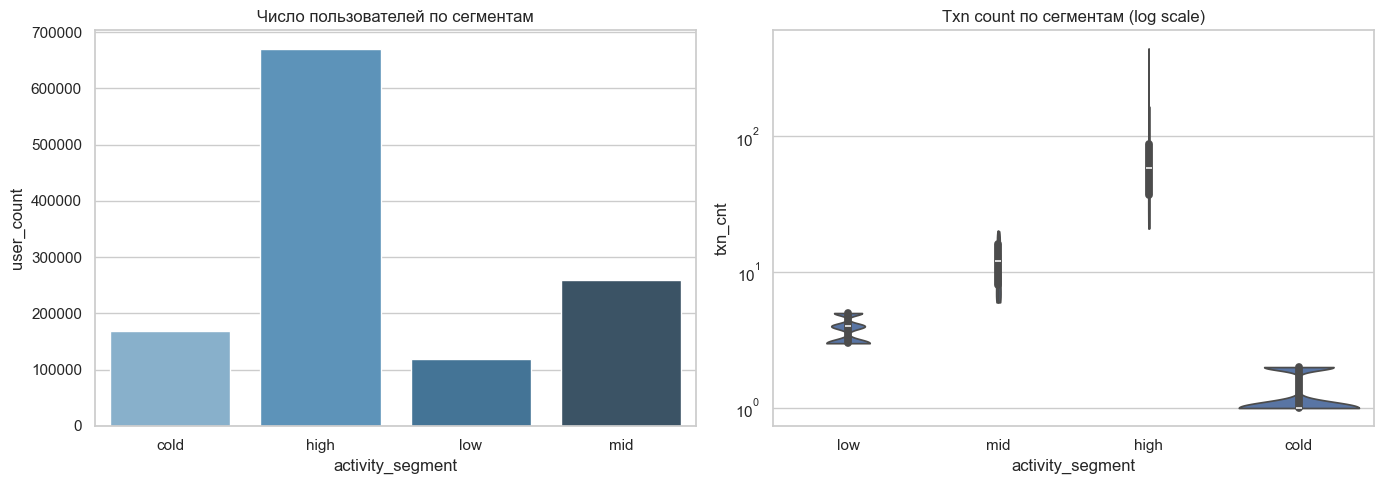

In [4]:
segment_summary = feature_df_full.groupby("activity_segment").agg(
    user_count=(ID_COL, "count"),
    mean_txn_cnt=("txn_cnt", "mean"),
    median_txn_cnt=("txn_cnt", "median"),
    mean_active_days_cnt=("active_days_cnt", "mean"),
    mean_unique_category_cnt=("unique_category_cnt", "mean"),
    mean_unique_mcc_cnt=("unique_mcc_cnt", "mean"),
    mean_unique_merchant_cnt=("unique_merchant_cnt", "mean"),
).reset_index().sort_values("activity_segment")
segment_summary.to_csv(ARTIFACT_DIR / "activity_segments_summary.csv", index=False)
display(segment_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=segment_summary, x="activity_segment", y="user_count", ax=axes[0], palette="Blues_d")
axes[0].set_title("Число пользователей по сегментам")
plot_df = feature_df_full.sample(n=min(15000, len(feature_df_full)), random_state=RANDOM_STATE)
sns.violinplot(data=plot_df, x="activity_segment", y="txn_cnt", ax=axes[1], cut=0)
axes[1].set_yscale("log")
axes[1].set_title("Txn count по сегментам (log scale)")
plt.tight_layout()
plt.show()

In [5]:
cold_share = float((feature_df_full["activity_segment"] == "cold").mean())
high_share = float((feature_df_full["activity_segment"] == "high").mean())
display(Markdown(
    f"**Краткий вывод.** Сегментация подтверждает сильную sparsity: доля `cold` пользователей составляет примерно {cold_share:.1%}, а `high`-сегмент заметно компактнее ({high_share:.1%}). Это значит, что качество similarity нужно оценивать отдельно по активности, а не только в среднем по всей базе."
))

**Краткий вывод.** Сегментация подтверждает сильную sparsity: доля `cold` пользователей составляет примерно 13.9%, а `high`-сегмент заметно компактнее (55.0%). Это значит, что качество similarity нужно оценивать отдельно по активности, а не только в среднем по всей базе.

## 3. Similarity по сегментам активности

Повторяем baseline-подход `log1p + RobustScaler` и сравниваем cosine / euclidean отдельно в каждом activity-сегменте.

,activity_segment,distance_metric,sample_size,mean_distance_to_nearest_neighbor,mean_distance_to_random_user,neighbor_random_gap,neighbor_stability_overlap_at_5
0,cold,cosine,1200,0.066626,0.800853,0.734227,0.688000
1,cold,euclidean,1200,1.423720,6.912734,5.489014,0.698000
2,low,cosine,1200,0.169267,0.888955,0.719688,0.711333
3,low,euclidean,1200,2.770006,6.700898,3.930892,0.715333
4,mid,cosine,1200,0.169416,0.851347,0.681931,0.686000
5,mid,euclidean,1200,3.775560,9.412356,5.636796,0.710667
6,high,cosine,1200,0.178097,0.845987,0.667890,0.691333
7,high,euclidean,1200,7.247923,18.849783,11.601859,0.696000


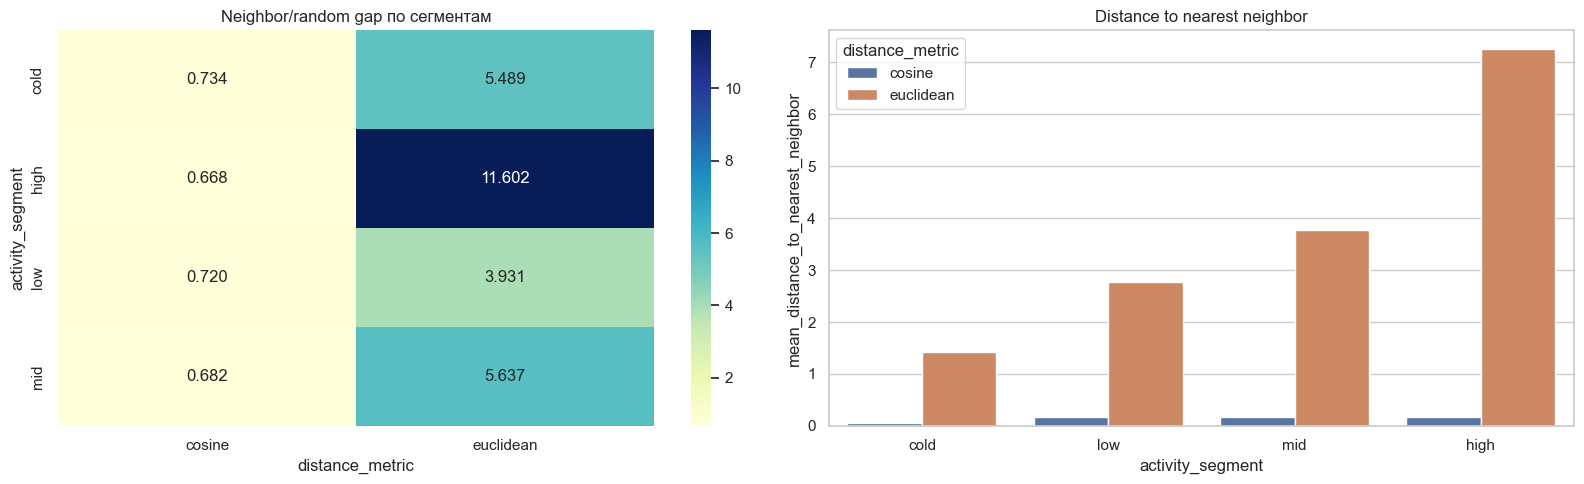

In [6]:
baseline_drop_cols = [ID_COL, "activity_segment"]
baseline_features = [c for c in feature_df_full.columns if c not in baseline_drop_cols]
segment_similarity_rows = []
segment_neighbor_store = {}
feature_lookup = feature_df_full[[ID_COL, "activity_segment", *[c for c in KEY_SCALE_COLS if c in feature_df_full.columns]]].copy()

for segment in ["cold", "low", "mid", "high"]:
    seg_df = feature_df_full[feature_df_full["activity_segment"] == segment].copy()
    if len(seg_df) < 20:
        warnings.warn(f"Segment {segment} слишком мал, пропускаю similarity.")
        continue
    seg_df = seg_df.sample(n=min(CONFIG["segment_sample_size"], len(seg_df)), random_state=RANDOM_STATE).reset_index(drop=True)
    X, _ = robust_matrix(seg_df[baseline_features])
    for metric in ["cosine", "euclidean"]:
        dist, ind = knn_run(X, metric)
        rnd = random_pair_distances(X, metric, seed=RANDOM_STATE)
        stability = overlapping_stability(X, metric, seg_df[ID_COL], seed=RANDOM_STATE)
        segment_similarity_rows.append({
            "activity_segment": segment,
            "distance_metric": metric,
            "sample_size": len(seg_df),
            "mean_distance_to_nearest_neighbor": float(dist[:, 0].mean()),
            "mean_distance_to_random_user": float(np.mean(rnd)),
            "neighbor_random_gap": float(np.mean(rnd) - dist[:, 0].mean()),
            "neighbor_stability_overlap_at_5": stability,
        })
        segment_neighbor_store[(segment, metric)] = {
            "user_ids": seg_df[ID_COL].tolist(),
            "indices": ind,
            "distances": dist,
        }

segment_similarity_df = pd.DataFrame(segment_similarity_rows)
segment_similarity_df.to_csv(ARTIFACT_DIR / "segment_similarity_metrics.csv", index=False)
display(segment_similarity_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pivot_gap = segment_similarity_df.pivot(index="activity_segment", columns="distance_metric", values="neighbor_random_gap")
sns.heatmap(pivot_gap, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Neighbor/random gap по сегментам")
sns.barplot(data=segment_similarity_df, x="activity_segment", y="mean_distance_to_nearest_neighbor", hue="distance_metric", ax=axes[1])
axes[1].set_title("Distance to nearest neighbor")
plt.tight_layout()
plt.show()

In [7]:
if not segment_similarity_df.empty:
    best_rows = segment_similarity_df.sort_values("neighbor_random_gap", ascending=False).head(2)
    txt = "; ".join([f"{r.activity_segment}/{r.distance_metric}: gap={r.neighbor_random_gap:.3f}" for r in best_rows.itertuples()])
    display(Markdown(f"**Краткий вывод.** Similarity ведет себя неодинаково по сегментам. Обычно самые полезные зоны видны там, где `neighbor_random_gap` выше и соседская структура стабильнее. Лидирующие комбинации в текущем запуске: {txt}."))

**Краткий вывод.** Similarity ведет себя неодинаково по сегментам. Обычно самые полезные зоны видны там, где `neighbor_random_gap` выше и соседская структура стабильнее. Лидирующие комбинации в текущем запуске: high/euclidean: gap=11.602; mid/euclidean: gap=5.637.

## 4. Semantic Neighbor Validation

Здесь проверяем, что ближайшие соседи действительно похожи по категориям, MCC и мерчантам, а не только по геометрии в feature space.

,activity_segment,distance_metric,pair_type,query_user,other_user,distance,jaccard_category,jaccard_mcc,jaccard_merchant,top3_category_overlap,top3_mcc_overlap,top3_merchant_overlap,category_distribution_cosine,mcc_distribution_cosine
0,cold,cosine,neighbor,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,4cb2e2e5ed730bfbd853b5bf1440e0c9373665c43dc3b4...,0.068628,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
1,cold,cosine,random,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,2d34dd86a934509c7a611da7bae9614c05f8d7a2b11f3f...,NaN,0.5,0.0,0.0,1.0,0.0,0.0,0.707107,0.0
2,cold,cosine,neighbor,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,61d4b8c3af0a35baff37929df9c7cf4245266b76cb7de4...,0.010963,1.0,1.0,0.0,1.0,1.0,0.0,1.000000,1.0
3,cold,cosine,random,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,528d5296c5db1a905d99136a6ce9c22c32c0bb738e5ef5...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
4,cold,cosine,random,7cb54040e38ecb15d51496e920b7813df9bfe6a3b7503e...,0d6dec1765fac769672e9d3291ed313494d2dc465fb2ec...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0


,activity_segment,distance_metric,pair_type,jaccard_category,jaccard_mcc,jaccard_merchant,top3_category_overlap,category_distribution_cosine,mcc_distribution_cosine
0,cold,cosine,neighbor,0.642857,0.478134,0.080661,0.673469,0.665784,0.494877
1,cold,cosine,random,0.112957,0.045958,0.006645,0.151163,0.129755,0.051328
2,cold,euclidean,neighbor,0.631554,0.463951,0.094569,0.661517,0.654112,0.480196
3,cold,euclidean,random,0.112957,0.045958,0.006645,0.151163,0.129755,0.051328
4,high,cosine,neighbor,0.485259,0.291321,0.013243,0.694274,0.869126,0.753440
5,high,cosine,random,0.342833,0.196901,0.008397,0.486542,0.666613,0.503719
6,high,euclidean,neighbor,0.485360,0.303386,0.014686,0.677083,0.897966,0.800757
7,high,euclidean,random,0.342833,0.196901,0.008397,0.486542,0.666613,0.503719
8,low,cosine,neighbor,0.328801,0.196267,0.012465,0.432503,0.503523,0.312051
9,low,cosine,random,0.160839,0.083724,0.002793,0.304975,0.246142,0.139874


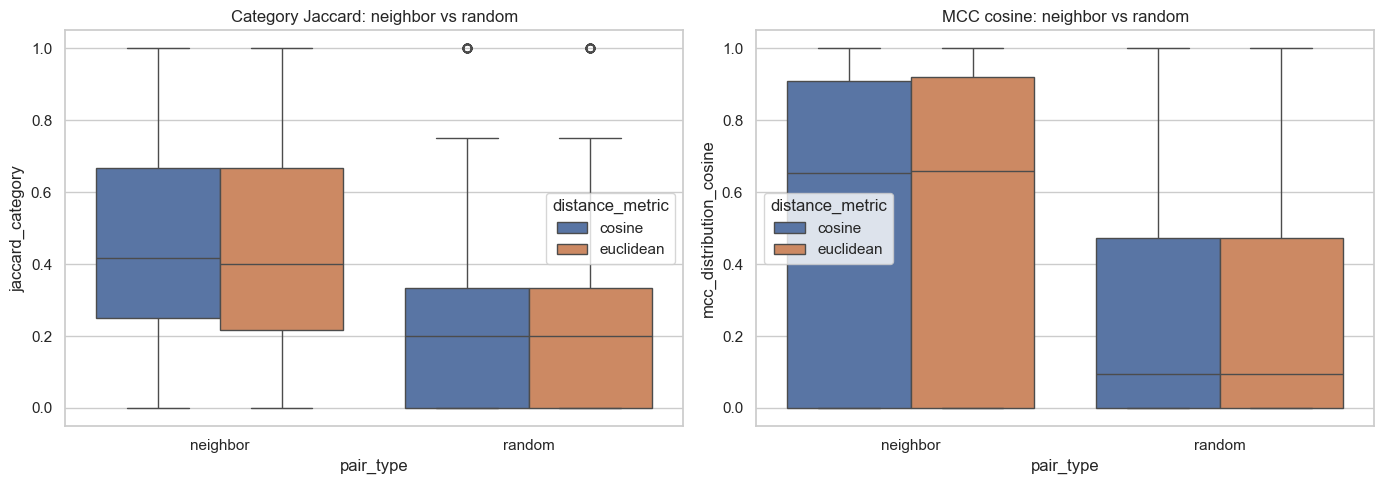

In [8]:
def top_items(values, k=3):
    return tuple(pd.Series(values).value_counts().head(k).index.tolist())


def jaccard(a, b):
    a = set(a)
    b = set(b)
    if not a and not b:
        return np.nan
    return len(a.intersection(b)) / len(a.union(b))


def top_overlap(a, b):
    a = set(a)
    b = set(b)
    if not a and not b:
        return np.nan
    return len(a.intersection(b)) / max(1, min(len(a), len(b), 3))


def counter_cosine(counter_a, counter_b):
    if not counter_a or not counter_b:
        return np.nan
    keys = set(counter_a).intersection(counter_b)
    num = float(sum(counter_a[k] * counter_b[k] for k in keys))
    da = float(np.sqrt(sum(v * v for v in counter_a.values())))
    db = float(np.sqrt(sum(v * v for v in counter_b.values())))
    if da == 0 or db == 0:
        return np.nan
    return num / (da * db)


def build_semantic_profiles(tx):
    profiles = {}
    for uid, part in tx.groupby(ID_COL):
        cat_counts = part["category_nm"].value_counts(normalize=True).to_dict()
        mcc_counts = part["merchant_type_code"].value_counts(normalize=True).to_dict()
        merch_counts = part["merchant_nm"].value_counts(normalize=True).to_dict()
        profiles[str(uid)] = {
            "category_set": set(part["category_nm"].astype(str)),
            "mcc_set": set(part["merchant_type_code"].astype(str)),
            "merchant_set": set(part["merchant_nm"].astype(str)),
            "top3_category": top_items(part["category_nm"].astype(str), 3),
            "top3_mcc": top_items(part["merchant_type_code"].astype(str), 3),
            "top3_merchant": top_items(part["merchant_nm"].astype(str), 3),
            "cat_counter": cat_counts,
            "mcc_counter": mcc_counts,
            "txn_cnt": len(part),
        }
    return profiles

semantic_users = set()
for payload in segment_neighbor_store.values():
    semantic_users.update(payload["user_ids"])
semantic_users = sorted(list(semantic_users))[: CONFIG["semantic_user_limit"]]
semantic_tx = load_transactions_for_users(semantic_users)
semantic_profiles = build_semantic_profiles(semantic_tx) if not semantic_tx.empty else {}
semantic_rows = []

for (segment, metric), payload in segment_neighbor_store.items():
    user_ids = np.asarray(payload["user_ids"])
    if len(user_ids) == 0:
        continue
    local_rng = np.random.default_rng(RANDOM_STATE)
    random_other = local_rng.integers(0, len(user_ids) - 1, size=len(user_ids))
    random_other += (random_other >= np.arange(len(user_ids))).astype(int)
    for i, uid in enumerate(user_ids):
        if uid not in semantic_profiles:
            continue
        neigh_uid = str(user_ids[payload["indices"][i, 0]])
        rand_uid = str(user_ids[random_other[i]])
        for pair_type, other_uid, dist in [("neighbor", neigh_uid, float(payload["distances"][i, 0])), ("random", rand_uid, np.nan)]:
            if other_uid not in semantic_profiles:
                continue
            a = semantic_profiles[str(uid)]
            b = semantic_profiles[str(other_uid)]
            semantic_rows.append({
                "activity_segment": segment,
                "distance_metric": metric,
                "pair_type": pair_type,
                "query_user": str(uid),
                "other_user": str(other_uid),
                "distance": dist,
                "jaccard_category": jaccard(a["category_set"], b["category_set"]),
                "jaccard_mcc": jaccard(a["mcc_set"], b["mcc_set"]),
                "jaccard_merchant": jaccard(a["merchant_set"], b["merchant_set"]),
                "top3_category_overlap": top_overlap(a["top3_category"], b["top3_category"]),
                "top3_mcc_overlap": top_overlap(a["top3_mcc"], b["top3_mcc"]),
                "top3_merchant_overlap": top_overlap(a["top3_merchant"], b["top3_merchant"]),
                "category_distribution_cosine": counter_cosine(a["cat_counter"], b["cat_counter"]),
                "mcc_distribution_cosine": counter_cosine(a["mcc_counter"], b["mcc_counter"]),
            })

semantic_df = pd.DataFrame(semantic_rows)
semantic_df.to_csv(ARTIFACT_DIR / "neighbor_vs_random_semantic_similarity.csv", index=False)
display(semantic_df.head())
if not semantic_df.empty:
    display(semantic_df.groupby(["activity_segment", "distance_metric", "pair_type"])[[
        "jaccard_category", "jaccard_mcc", "jaccard_merchant", "top3_category_overlap", "category_distribution_cosine", "mcc_distribution_cosine"
    ]].mean().reset_index())
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=semantic_df, x="pair_type", y="jaccard_category", hue="distance_metric", ax=axes[0])
    axes[0].set_title("Category Jaccard: neighbor vs random")
    sns.boxplot(data=semantic_df, x="pair_type", y="mcc_distribution_cosine", hue="distance_metric", ax=axes[1])
    axes[1].set_title("MCC cosine: neighbor vs random")
    plt.tight_layout()
    plt.show()

In [9]:
if semantic_df.empty:
    display(Markdown("**Краткий вывод.** Транзакционных данных для semantic validation недостаточно, поэтому секция была пропущена без ошибки."))
else:
    neigh = semantic_df[semantic_df["pair_type"] == "neighbor"]
    rnd = semantic_df[semantic_df["pair_type"] == "random"]
    display(Markdown(
        f"**Краткий вывод.** По semantic-метрикам соседи должны выигрывать у случайных пар. В текущем запуске средний `jaccard_category` у соседей = {neigh['jaccard_category'].mean():.3f}, у random = {rnd['jaccard_category'].mean():.3f}; по `mcc_distribution_cosine` разница также видна: {neigh['mcc_distribution_cosine'].mean():.3f} против {rnd['mcc_distribution_cosine'].mean():.3f}."
    ))

**Краткий вывод.** По semantic-метрикам соседи должны выигрывать у случайных пар. В текущем запуске средний `jaccard_category` у соседей = 0.471, у random = 0.210; по `mcc_distribution_cosine` разница также видна: 0.542 против 0.255.

## 5. Activity Scale Bias Analysis

Проверяем, не сводится ли similarity в основном к близости по масштабу активности.

,activity_segment,distance_metric,pair_type,query_user,other_user,distance,jaccard_category,jaccard_mcc,jaccard_merchant,top3_category_overlap,top3_mcc_overlap,top3_merchant_overlap,category_distribution_cosine,mcc_distribution_cosine,query_party_rk,query_activity_segment,query_txn_cnt,query_active_days_cnt,query_unique_category_cnt,query_unique_mcc_cnt,query_unique_merchant_cnt,other_party_rk,other_activity_segment,other_txn_cnt,other_active_days_cnt,other_unique_category_cnt,other_unique_mcc_cnt,other_unique_merchant_cnt,abs_log1p_txn_cnt_diff,abs_active_days_cnt_diff,abs_unique_category_cnt_diff,abs_unique_mcc_cnt_diff,abs_unique_merchant_cnt_diff
0,cold,cosine,neighbor,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,4cb2e2e5ed730bfbd853b5bf1440e0c9373665c43dc3b4...,0.068628,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,cold,1.0,1.0,1.0,1.0,1.0,4cb2e2e5ed730bfbd853b5bf1440e0c9373665c43dc3b4...,cold,1.0,1.0,1.0,1.0,1.0,0.000000,0.0,0.0,0.0,0.0
1,cold,cosine,random,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,2d34dd86a934509c7a611da7bae9614c05f8d7a2b11f3f...,NaN,0.5,0.0,0.0,1.0,0.0,0.0,0.707107,0.0,2b687f60c4443ef16d1db53a059ba94f87cafb22787cb4...,cold,1.0,1.0,1.0,1.0,1.0,2d34dd86a934509c7a611da7bae9614c05f8d7a2b11f3f...,cold,2.0,2.0,2.0,2.0,2.0,0.405465,1.0,1.0,1.0,1.0
2,cold,cosine,neighbor,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,61d4b8c3af0a35baff37929df9c7cf4245266b76cb7de4...,0.010963,1.0,1.0,0.0,1.0,1.0,0.0,1.000000,1.0,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,cold,1.0,1.0,1.0,1.0,1.0,61d4b8c3af0a35baff37929df9c7cf4245266b76cb7de4...,cold,1.0,1.0,1.0,1.0,1.0,0.000000,0.0,0.0,0.0,0.0
3,cold,cosine,random,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,528d5296c5db1a905d99136a6ce9c22c32c0bb738e5ef5...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,064a24fc17a5d1d5826a56d4bd92437b9d7cb2dfba66bd...,cold,1.0,1.0,1.0,1.0,1.0,528d5296c5db1a905d99136a6ce9c22c32c0bb738e5ef5...,cold,1.0,1.0,1.0,1.0,1.0,0.000000,0.0,0.0,0.0,0.0
4,cold,cosine,random,7cb54040e38ecb15d51496e920b7813df9bfe6a3b7503e...,0d6dec1765fac769672e9d3291ed313494d2dc465fb2ec...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,7cb54040e38ecb15d51496e920b7813df9bfe6a3b7503e...,cold,1.0,1.0,1.0,1.0,1.0,0d6dec1765fac769672e9d3291ed313494d2dc465fb2ec...,cold,2.0,2.0,2.0,2.0,2.0,0.405465,1.0,1.0,1.0,1.0


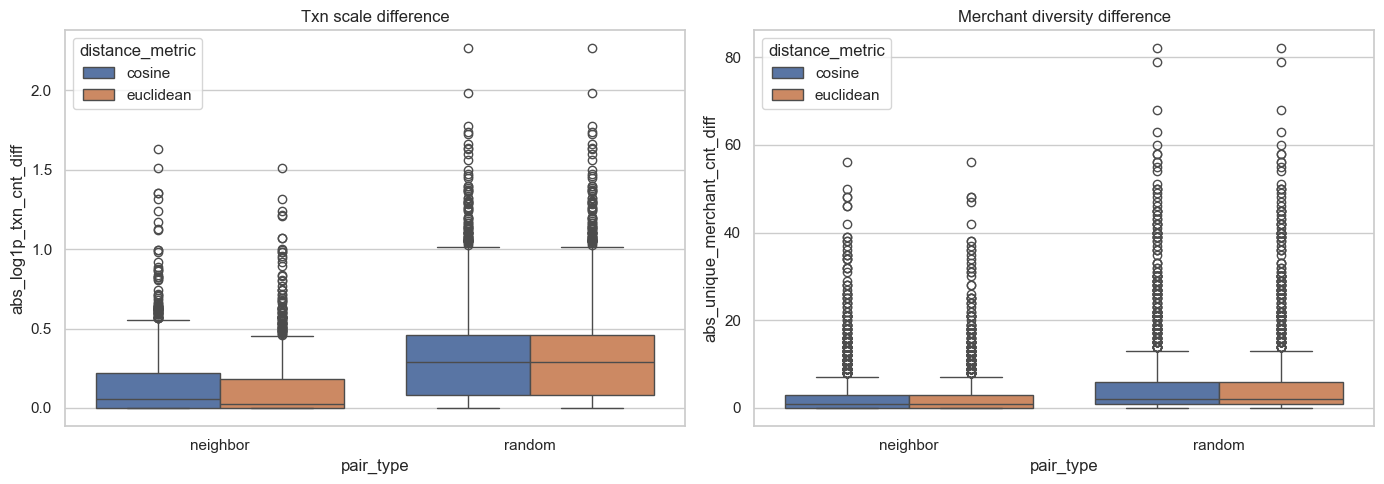

In [10]:
if semantic_df.empty:
    bias_df = pd.DataFrame()
else:
    bias_df = semantic_df.merge(feature_lookup.add_prefix("query_"), left_on="query_user", right_on="query_party_rk", how="left")
    bias_df = bias_df.merge(feature_lookup.add_prefix("other_"), left_on="other_user", right_on="other_party_rk", how="left")
    bias_df["abs_log1p_txn_cnt_diff"] = np.abs(np.log1p(bias_df["query_txn_cnt"].astype(float)) - np.log1p(bias_df["other_txn_cnt"].astype(float)))
    bias_df["abs_active_days_cnt_diff"] = np.abs(bias_df["query_active_days_cnt"].astype(float) - bias_df["other_active_days_cnt"].astype(float))
    bias_df["abs_unique_category_cnt_diff"] = np.abs(bias_df["query_unique_category_cnt"].astype(float) - bias_df["other_unique_category_cnt"].astype(float))
    bias_df["abs_unique_mcc_cnt_diff"] = np.abs(bias_df["query_unique_mcc_cnt"].astype(float) - bias_df["other_unique_mcc_cnt"].astype(float))
    bias_df["abs_unique_merchant_cnt_diff"] = np.abs(bias_df["query_unique_merchant_cnt"].astype(float) - bias_df["other_unique_merchant_cnt"].astype(float))
    bias_df.to_csv(ARTIFACT_DIR / "activity_scale_neighbor_vs_random.csv", index=False)
    display(bias_df.head())
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=bias_df, x="pair_type", y="abs_log1p_txn_cnt_diff", hue="distance_metric", ax=axes[0])
    axes[0].set_title("Txn scale difference")
    sns.boxplot(data=bias_df, x="pair_type", y="abs_unique_merchant_cnt_diff", hue="distance_metric", ax=axes[1])
    axes[1].set_title("Merchant diversity difference")
    plt.tight_layout()
    plt.show()

In [11]:
if bias_df.empty:
    display(Markdown("**Краткий вывод.** Bias-анализ пропущен, потому что pair-level semantic dataframe пустой."))
else:
    grp = bias_df.groupby("pair_type")[["abs_log1p_txn_cnt_diff", "abs_unique_category_cnt_diff", "abs_unique_merchant_cnt_diff"]].mean()
    display(Markdown(
        f"**Краткий вывод.** Если neighbor-пары системно ближе random-пар по scale-признакам, similarity частично driven by scale. В текущем запуске средняя разница по `log1p(txn_cnt)` равна {grp.loc['neighbor', 'abs_log1p_txn_cnt_diff']:.3f} у neighbors против {grp.loc['random', 'abs_log1p_txn_cnt_diff']:.3f} у random."
    ))

**Краткий вывод.** Если neighbor-пары системно ближе random-пар по scale-признакам, similarity частично driven by scale. В текущем запуске средняя разница по `log1p(txn_cnt)` равна 0.133 у neighbors против 0.355 у random.

## 6. Holdout Time-Based Validation

Если есть транзакционные timestamps, переходим к временной валидации: history vs future, similarity-рекомендации против popularity и repeat baseline.

,feature_set,distance_metric,target,baseline,Recall@5,Recall@10,HitRate@5,HitRate@10,users_evaluated
0,hybrid,cosine,category_nm,neighbor_similarity,0.651993,0.781345,0.965000,0.976667,1200
1,hybrid,cosine,category_nm,global_popularity,0.620649,0.806535,0.956667,0.981667,1200
2,hybrid,cosine,category_nm,user_repeat,0.695954,0.787233,0.970833,0.974167,1200
3,hybrid,cosine,merchant_type_code,neighbor_similarity,0.501436,0.598472,0.924167,0.947500,1200
4,hybrid,cosine,merchant_type_code,global_popularity,0.422206,0.590639,0.878333,0.925000,1200
5,hybrid,cosine,merchant_type_code,user_repeat,0.584183,0.683486,0.954167,0.961667,1200
6,hybrid,cosine,merchant_nm,neighbor_similarity,0.044571,0.052308,0.229167,0.262500,1200
7,hybrid,cosine,merchant_nm,global_popularity,0.061975,0.079672,0.327500,0.388333,1200
8,hybrid,cosine,merchant_nm,user_repeat,0.325439,0.406255,0.833333,0.872500,1200
9,hybrid,euclidean,category_nm,neighbor_similarity,0.645656,0.785537,0.964167,0.979167,1200


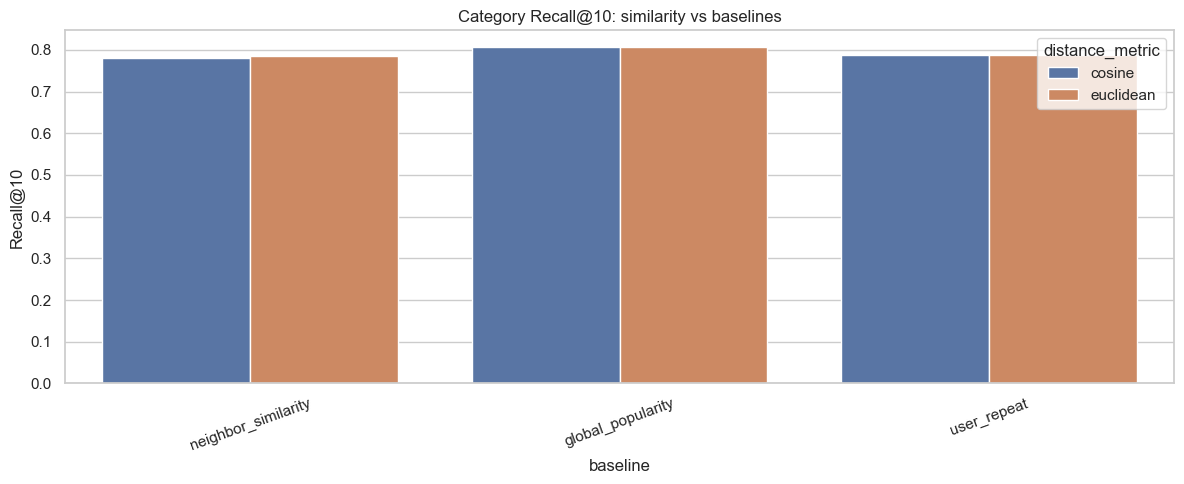

In [12]:
def entropy_from_series(s):
    p = s.value_counts(normalize=True)
    return float(-(p * np.log(np.clip(p, 1e-12, None))).sum()) if len(p) else np.nan


def build_tx_feature_frame(tx, feature_set="hybrid", merchant_cutoff=10):
    if tx.empty:
        return pd.DataFrame()
    work = tx.copy()
    if "merchant_nm" in work.columns:
        freq = work["merchant_nm"].value_counts()
        rare = freq[freq < merchant_cutoff].index
        work.loc[work["merchant_nm"].isin(rare), "merchant_nm"] = "merchant_other"
    ref_ts = work["real_transaction_dttm"].max()
    base = work.groupby(ID_COL).agg(
        txn_cnt=("real_transaction_dttm", "size"),
        active_days_cnt=("real_transaction_dttm", lambda x: x.dt.date.nunique()),
        unique_category_cnt=("category_nm", "nunique"),
        unique_mcc_cnt=("merchant_type_code", "nunique"),
        unique_merchant_cnt=("merchant_nm", "nunique"),
        last_txn=("real_transaction_dttm", "max"),
    )
    base["recency_days"] = (ref_ts - base["last_txn"]).dt.days.astype(float)
    base["frequency"] = base["txn_cnt"] / np.clip(base["active_days_cnt"], 1, None)
    base["share_weekend_txn"] = work.groupby(ID_COL)["is_weekend"].mean().astype(float)
    hour_share = work.assign(
        is_night=work["hour"].between(0, 5),
        is_morning=work["hour"].between(6, 11),
        is_afternoon=work["hour"].between(12, 16),
        is_evening=work["hour"].between(17, 23),
    ).groupby(ID_COL)[["is_night", "is_morning", "is_afternoon", "is_evening"]].mean()
    hour_share.columns = ["share_night_txn", "share_morning_txn", "share_afternoon_txn", "share_evening_txn"]
    cat_entropy = work.groupby(ID_COL)["category_nm"].apply(entropy_from_series).rename("category_entropy")
    mcc_entropy = work.groupby(ID_COL)["merchant_type_code"].apply(entropy_from_series).rename("mcc_entropy")
    top_cat = work["category_nm"].value_counts().head(15).index
    top_mcc = work["merchant_type_code"].value_counts().head(15).index
    top_merch = work["merchant_nm"].value_counts().head(20).index
    cat_share = pd.crosstab(work[ID_COL], work["category_nm"], normalize="index").reindex(columns=top_cat, fill_value=0)
    cat_share.columns = [f"cat_share_{str(c).lower()}" for c in cat_share.columns]
    mcc_share = pd.crosstab(work[ID_COL], work["merchant_type_code"], normalize="index").reindex(columns=top_mcc, fill_value=0)
    mcc_share.columns = [f"mcc_share_{str(c)}" for c in mcc_share.columns]
    merch_share = pd.crosstab(work[ID_COL], work["merchant_nm"], normalize="index").reindex(columns=top_merch, fill_value=0)
    merch_share.columns = [f"merchant_share_{i}" for i in range(merch_share.shape[1])]
    out = base.drop(columns=["last_txn"]).join(hour_share).join(cat_entropy).join(mcc_entropy).join(cat_share).join(mcc_share).join(merch_share)
    if feature_set == "structural":
        keep = [c for c in out.columns if c.startswith("cat_share_") or c.startswith("mcc_share_") or c.startswith("merchant_share_") or c.startswith("share_") or c in ["category_entropy", "mcc_entropy", "recency_days", "frequency"]]
        out = out[keep]
    return out.reset_index()


def split_history_future(tx, holdout_ratio=0.2, min_txn=5):
    if tx.empty or ID_COL not in tx.columns or "real_transaction_dttm" not in tx.columns:
        return pd.DataFrame(), pd.DataFrame()
    hist_parts = []
    fut_parts = []
    for _, part in tx.sort_values([ID_COL, "real_transaction_dttm"]).groupby(ID_COL):
        if len(part) < min_txn:
            continue
        split = max(1, int(np.floor(len(part) * (1 - holdout_ratio))))
        split = min(split, len(part) - 1)
        hist_parts.append(part.iloc[:split])
        fut_parts.append(part.iloc[split:])
    if not hist_parts or not fut_parts:
        return pd.DataFrame(), pd.DataFrame()
    return pd.concat(hist_parts, ignore_index=True), pd.concat(fut_parts, ignore_index=True)


def recommendation_metrics(target_lists, pred_lists, k):
    recalls = []
    hits = []
    for true_items, pred_items in zip(target_lists, pred_lists):
        true_set = set(true_items)
        pred = list(pred_items)[:k]
        if not true_set:
            continue
        hit = len(true_set.intersection(pred)) > 0
        recall = len(true_set.intersection(pred)) / len(true_set)
        hits.append(float(hit))
        recalls.append(recall)
    return float(np.mean(recalls)) if recalls else np.nan, float(np.mean(hits)) if hits else np.nan


def evaluate_holdout(history_tx, future_tx, feature_set, metric):
    hist_features = build_tx_feature_frame(history_tx, feature_set=feature_set, merchant_cutoff=CONFIG["merchant_frequency_cutoff"])
    if hist_features.empty:
        return pd.DataFrame()
    common_users = sorted(set(hist_features[ID_COL]).intersection(set(future_tx[ID_COL])))
    hist_features = hist_features[hist_features[ID_COL].isin(common_users)].reset_index(drop=True)
    history_tx = history_tx[history_tx[ID_COL].isin(common_users)].copy()
    future_tx = future_tx[future_tx[ID_COL].isin(common_users)].copy()
    if len(hist_features) < 30:
        return pd.DataFrame()
    X, _ = robust_matrix(hist_features.drop(columns=[ID_COL]))
    dist, ind = knn_run(X, metric)
    user_ids = hist_features[ID_COL].tolist()
    future_targets = {col: future_tx.groupby(ID_COL)[col].apply(lambda s: list(pd.unique(s.astype(str)))).to_dict() for col in ["category_nm", "merchant_type_code", "merchant_nm"] if col in future_tx.columns}
    hist_pop = {col: history_tx[col].astype(str).value_counts().index.tolist() for col in future_targets}
    hist_user = {col: history_tx.groupby(ID_COL)[col].apply(lambda s: s.astype(str).value_counts().index.tolist()).to_dict() for col in future_targets}
    rows = []
    for target_col in future_targets:
        neighbor_preds = []
        pop_preds = []
        repeat_preds = []
        true_lists = []
        for i, uid in enumerate(user_ids):
            neigh_ids = [user_ids[j] for j in ind[i]]
            neigh_tx = history_tx[history_tx[ID_COL].isin(neigh_ids)]
            pred = neigh_tx[target_col].astype(str).value_counts().index.tolist()
            neighbor_preds.append(pred)
            pop_preds.append(hist_pop[target_col])
            repeat_preds.append(hist_user[target_col].get(uid, []))
            true_lists.append(future_targets[target_col].get(uid, []))
        for baseline_name, preds in [("neighbor_similarity", neighbor_preds), ("global_popularity", pop_preds), ("user_repeat", repeat_preds)]:
            rec5, hit5 = recommendation_metrics(true_lists, preds, 5)
            rec10, hit10 = recommendation_metrics(true_lists, preds, 10)
            rows.append({
                "feature_set": feature_set,
                "distance_metric": metric,
                "target": target_col,
                "baseline": baseline_name,
                "Recall@5": rec5,
                "Recall@10": rec10,
                "HitRate@5": hit5,
                "HitRate@10": hit10,
                "users_evaluated": len(true_lists),
            })
    return pd.DataFrame(rows)

holdout_candidates = feature_df_full[feature_df_full["txn_cnt"] >= CONFIG["min_transactions_threshold"]][ID_COL].sample(
    n=min(CONFIG["holdout_user_limit"], int((feature_df_full["txn_cnt"] >= CONFIG["min_transactions_threshold"]).sum())),
    random_state=RANDOM_STATE,
).astype(str).tolist() if (TX_PARQUET_PATH.exists() or TX_CSV_FALLBACK_PATH.exists()) else []

holdout_tx = load_transactions_for_users(holdout_candidates)
history_tx, future_tx = split_history_future(holdout_tx, holdout_ratio=CONFIG["holdout_ratio"], min_txn=CONFIG["min_transactions_threshold"])
holdout_results = []
if not history_tx.empty and not future_tx.empty:
    for metric in ["cosine", "euclidean"]:
        res = evaluate_holdout(history_tx, future_tx, feature_set="hybrid", metric=metric)
        if not res.empty:
            holdout_results.append(res)
holdout_results_df = pd.concat(holdout_results, ignore_index=True) if holdout_results else pd.DataFrame()
holdout_results_df.to_csv(ARTIFACT_DIR / "holdout_validation_results.csv", index=False)
display(holdout_results_df.head(20))
if not holdout_results_df.empty:
    plt.figure(figsize=(12, 5))
    plot_df = holdout_results_df[holdout_results_df["target"] == "category_nm"].copy()
    sns.barplot(data=plot_df, x="baseline", y="Recall@10", hue="distance_metric")
    plt.title("Category Recall@10: similarity vs baselines")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [13]:
if holdout_results_df.empty:
    display(Markdown("**Краткий вывод.** Holdout validation была пропущена или дала пустой результат: либо не хватило транзакционных данных, либо после temporal split осталось слишком мало пользователей."))
else:
    cat_rows = holdout_results_df[holdout_results_df["target"] == "category_nm"]
    top = cat_rows.sort_values("Recall@10", ascending=False).head(3)
    txt = "; ".join([f"{r.baseline}/{r.distance_metric}: Recall@10={r._6:.3f}" for r in top.itertuples()])
    display(Markdown(f"**Краткий вывод.** Временная валидация показывает, помогает ли similarity предсказывать будущие действия. Лучшие результаты по категориям в текущем запуске: {txt}."))

**Краткий вывод.** Временная валидация показывает, помогает ли similarity предсказывать будущие действия. Лучшие результаты по категориям в текущем запуске: global_popularity/cosine: Recall@10=0.807; global_popularity/euclidean: Recall@10=0.807; user_repeat/euclidean: Recall@10=0.787.

## 7. Новые наборы признаков

Сравниваем два дополнительных варианта профиля: `structural` и `hybrid`. Оцениваем их по semantic-сигналам и по temporal holdout.

In [14]:
def feature_set_semantic_score(tx, feature_set, metric):
    feat = build_tx_feature_frame(tx, feature_set=feature_set, merchant_cutoff=CONFIG["merchant_frequency_cutoff"])
    if feat.empty or len(feat) < 30:
        return None
    X, _ = robust_matrix(feat.drop(columns=[ID_COL]))
    dist, ind = knn_run(X, metric)
    profiles = build_semantic_profiles(tx)
    rows = []
    ids = feat[ID_COL].astype(str).tolist()
    for i, uid in enumerate(ids[: min(500, len(ids))]):
        other = ids[ind[i, 0]]
        if uid not in profiles or other not in profiles:
            continue
        a = profiles[uid]
        b = profiles[other]
        rows.append({
            "mean_category_jaccard": jaccard(a["category_set"], b["category_set"]),
            "mean_mcc_cosine": counter_cosine(a["mcc_counter"], b["mcc_counter"]),
            "mean_top3_category_overlap": top_overlap(a["top3_category"], b["top3_category"]),
        })
    if not rows:
        return None
    out = pd.DataFrame(rows).mean().to_dict()
    out["sample_users"] = len(rows)
    return out

feature_set_rows = []
if not history_tx.empty and not future_tx.empty:
    for feature_set in ["structural", "hybrid"]:
        semantic_score = feature_set_semantic_score(history_tx, feature_set, "cosine")
        for metric in ["cosine", "euclidean"]:
            hold = evaluate_holdout(history_tx, future_tx, feature_set=feature_set, metric=metric)
            if hold.empty:
                continue
            category_row = hold[(hold["target"] == "category_nm") & (hold["baseline"] == "neighbor_similarity")]
            if category_row.empty:
                continue
            base = category_row.iloc[0].to_dict()
            row = {
                "feature_set": feature_set,
                "distance_metric": metric,
                "Recall@5": base.get("Recall@5"),
                "Recall@10": base.get("Recall@10"),
                "HitRate@5": base.get("HitRate@5"),
                "HitRate@10": base.get("HitRate@10"),
            }
            if semantic_score is not None:
                row.update(semantic_score)
            feature_set_rows.append(row)
feature_set_comparison_df = pd.DataFrame(feature_set_rows)
feature_set_comparison_df.to_csv(ARTIFACT_DIR / "feature_set_comparison.csv", index=False)
display(feature_set_comparison_df)

,feature_set,distance_metric,Recall@5,Recall@10,HitRate@5,HitRate@10,mean_category_jaccard,mean_mcc_cosine,mean_top3_category_overlap,sample_users
0,structural,cosine,0.653364,0.784146,0.967500,0.980000,0.440395,0.655569,0.693000,500
1,structural,euclidean,0.645650,0.787126,0.966667,0.979167,0.440395,0.655569,0.693000,500
2,hybrid,cosine,0.651993,0.781345,0.965000,0.976667,0.449237,0.645630,0.687667,500
3,hybrid,euclidean,0.645656,0.785537,0.964167,0.979167,0.449237,0.645630,0.687667,500


In [15]:
if feature_set_comparison_df.empty:
    display(Markdown("**Краткий вывод.** Сравнение feature sets оказалось пустым: либо holdout-выборка мала, либо транзакционных данных недостаточно."))
else:
    best_fs = feature_set_comparison_df.sort_values(["Recall@10", "mean_category_jaccard"], ascending=False).iloc[0]
    display(Markdown(
        f"**Краткий вывод.** Среди новых наборов признаков сейчас лидирует `feature_set={best_fs['feature_set']}` с метрикой `{best_fs['distance_metric']}`: Recall@10={best_fs['Recall@10']:.3f}, semantic category overlap={best_fs.get('mean_category_jaccard', np.nan):.3f}."
    ))

**Краткий вывод.** Среди новых наборов признаков сейчас лидирует `feature_set=structural` с метрикой `euclidean`: Recall@10=0.787, semantic category overlap=0.440.

## 8. Qualitative Neighbor Audit

Делаем ручной аудит 30 случайных пользователей: смотрим их топ-паттерны и ближайших соседей в наиболее удачной конфигурации.

In [16]:
audit_df = pd.DataFrame()
if not history_tx.empty:
    audit_feature_set = "hybrid"
    audit_metric = "cosine"
    if not feature_set_comparison_df.empty:
        best = feature_set_comparison_df.sort_values(["Recall@10", "mean_category_jaccard"], ascending=False).iloc[0]
        audit_feature_set = best["feature_set"]
        audit_metric = best["distance_metric"]
    audit_feat = build_tx_feature_frame(history_tx, feature_set=audit_feature_set, merchant_cutoff=CONFIG["merchant_frequency_cutoff"])
    if not audit_feat.empty and len(audit_feat) >= 40:
        X, _ = robust_matrix(audit_feat.drop(columns=[ID_COL]))
        dist, ind = knn_run(X, audit_metric)
        profiles = build_semantic_profiles(history_tx)
        ids = audit_feat[ID_COL].astype(str).tolist()
        chosen = rng.choice(len(ids), size=min(CONFIG["audit_user_count"], len(ids)), replace=False)
        rows = []
        for i in chosen:
            uid = ids[i]
            for rank, j in enumerate(ind[i], start=1):
                other = ids[j]
                a = profiles.get(uid, {})
                b = profiles.get(other, {})
                rows.append({
                    "feature_set": audit_feature_set,
                    "distance_metric": audit_metric,
                    "query_user": uid,
                    "neighbor_rank": rank,
                    "neighbor_user": other,
                    "distance": float(dist[i, rank - 1]),
                    "query_top_categories": ", ".join(a.get("top3_category", ())),
                    "query_top_mcc": ", ".join(a.get("top3_mcc", ())),
                    "query_top_merchants": ", ".join(a.get("top3_merchant", ())),
                    "neighbor_top_categories": ", ".join(b.get("top3_category", ())),
                    "neighbor_top_mcc": ", ".join(b.get("top3_mcc", ())),
                    "neighbor_top_merchants": ", ".join(b.get("top3_merchant", ())),
                    "category_jaccard": jaccard(a.get("category_set", set()), b.get("category_set", set())),
                    "mcc_jaccard": jaccard(a.get("mcc_set", set()), b.get("mcc_set", set())),
                    "merchant_jaccard": jaccard(a.get("merchant_set", set()), b.get("merchant_set", set())),
                })
        audit_df = pd.DataFrame(rows)
        audit_df.to_csv(ARTIFACT_DIR / "qualitative_neighbors_audit.csv", index=False)
display(audit_df.head(20))

,feature_set,distance_metric,query_user,neighbor_rank,neighbor_user,distance,query_top_categories,query_top_mcc,query_top_merchants,neighbor_top_categories,neighbor_top_mcc,neighbor_top_merchants,category_jaccard,mcc_jaccard,merchant_jaccard
0,structural,euclidean,a23bc458071f6876cc4f4337034b2b01f935797a0b628e...,1,a8eadebf9a23f4b026ded97c6dd035c992a7bf17cf1667...,2.878211,"Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 5331","MAGNIT MM BYLONSKY, PYATEROCHKA 352, VKUSVILL ...","Супермаркеты, Сервисные услуги, Фаст Фуд","5411, 5964, 5814","PYATEROCHKA 1954, wildberries, Dodo Pitstsa, P...",0.600000,0.500000,0.000000
1,structural,euclidean,a23bc458071f6876cc4f4337034b2b01f935797a0b628e...,2,ae20fe9f32e9e5dcbf8f6de5623bf2be1b5eae01ae5c19...,3.154119,"Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 5331","MAGNIT MM BYLONSKY, PYATEROCHKA 352, VKUSVILL ...","Супермаркеты, Ж/д билеты, Фаст Фуд","5411, 4112, 5814","PYATEROCHKA 11876, Liski, kassa, SHTYKOV 14",0.600000,0.500000,0.000000
2,structural,euclidean,a23bc458071f6876cc4f4337034b2b01f935797a0b628e...,3,5b20560cc3fb92d779e90bc80016de50f88bb081d3382e...,3.541388,"Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 5331","MAGNIT MM BYLONSKY, PYATEROCHKA 352, VKUSVILL ...","Супермаркеты, Фаст Фуд, Дом/Ремонт","5411, 5814, 5499","SEMISHAGOFF, LENTA-709, REAL 63",0.333333,0.250000,0.031250
3,structural,euclidean,a23bc458071f6876cc4f4337034b2b01f935797a0b628e...,4,4f53b82390a650883d190b99a5173c12d17b617344b60f...,3.580859,"Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 5331","MAGNIT MM BYLONSKY, PYATEROCHKA 352, VKUSVILL ...","Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 7278","MAGNIT GM Krasnodar 4, MIGRACIYA MM, PODELI",0.600000,0.375000,0.000000
4,structural,euclidean,a23bc458071f6876cc4f4337034b2b01f935797a0b628e...,5,f1e48b5d6c146b7d88896bbe0093376981405d7fea1ce0...,3.592294,"Супермаркеты, Фаст Фуд, Разные товары","5411, 5814, 5331","MAGNIT MM BYLONSKY, PYATEROCHKA 352, VKUSVILL ...","Супермаркеты, Разные товары, Образование","5411, 5311, 8299","PYATEROCHKA 7916, PYATEROCHKA 9641, MAGNIT MK ...",0.400000,0.285714,0.000000
5,structural,euclidean,834e427f60e77b0b0f4adc0fae0e202253a3af2b6f34b2...,1,8e755aaa79a05f75b4ce7f67a4156c5fc92f53a4e56583...,6.271878,"Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","PYATEROCHKA 22037, PYATEROCHKA 18724, YandexGo","Супермаркеты, Фаст Фуд, Аптеки","5411, 5814, 5912","Servisy Yandeksa, AROMATNYJ MIR, PYATEROCHKA 1...",0.666667,0.238095,0.000000
6,structural,euclidean,834e427f60e77b0b0f4adc0fae0e202253a3af2b6f34b2...,2,978d7614d4ba262084405b08b260cd58ba84d84b9095af...,6.531579,"Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","PYATEROCHKA 22037, PYATEROCHKA 18724, YandexGo","Супермаркеты, Транспорт, Аптеки","5462, 5411, 5499","IP LISOVEC I.G., PLATA ZA PROEZD TKPAY, MAGNIT...",0.500000,0.266667,0.000000
7,structural,euclidean,834e427f60e77b0b0f4adc0fae0e202253a3af2b6f34b2...,3,e3dc12755a062b17a8c8852efe3d8d84da8e5da1ca5960...,6.568897,"Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","PYATEROCHKA 22037, PYATEROCHKA 18724, YandexGo","Супермаркеты, Аптеки, unknown","5411, 5912, 5499","PEREKRESTOK YUZH.SHOSS, KEUNEQR, SPAR N98SBP",0.400000,0.238095,0.000000
8,structural,euclidean,834e427f60e77b0b0f4adc0fae0e202253a3af2b6f34b2...,4,f6529737ca834712343ec1429d57eab9334b7af7c96cd4...,6.866182,"Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","PYATEROCHKA 22037, PYATEROCHKA 18724, YandexGo","Супермаркеты, Аптеки, Разные товары","5411, 5912, 5943","PYATEROCHKA, VKUSVILL_5063_1, APTEKA LILANI..",0.545455,0.200000,0.000000
9,structural,euclidean,834e427f60e77b0b0f4adc0fae0e202253a3af2b6f34b2...,5,198c6ab5726c29c96cbed65de5ad406eaccde447b86d77...,6.873045,"Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","PYATEROCHKA 22037, PYATEROCHKA 18724, YandexGo","Супермаркеты, Аптеки, Фаст Фуд","5411, 5912, 5814","RUSSKIJ APPETIT, MAGAZIN ALKOBREND, PYATEROCHK...",0.444444,0.300000,0.045455


In [17]:
if audit_df.empty:
    display(Markdown("**Краткий вывод.** Qualitative audit пропущен: для выбранной конфигурации не удалось собрать достаточный набор history-профилей."))
else:
    display(Markdown(
        f"**Краткий вывод.** Качественный аудит собран для {audit_df['query_user'].nunique()} пользователей. Таблица `qualitative_neighbors_audit.csv` предназначена для ручной проверки того, насколько соседи выглядят осмысленно на уровне топ-категорий, MCC и мерчантов."
    ))

**Краткий вывод.** Качественный аудит собран для 30 пользователей. Таблица `qualitative_neighbors_audit.csv` предназначена для ручной проверки того, насколько соседи выглядят осмысленно на уровне топ-категорий, MCC и мерчантов.

## 9. Финальная сводка

Собираем итоговую таблицу, которая объединяет сегментную геометрию, semantic overlap и holdout validation.

In [18]:
semantic_summary = pd.DataFrame()
if not semantic_df.empty:
    semantic_summary = semantic_df.groupby(["activity_segment", "distance_metric", "pair_type"])[[
        "jaccard_category", "jaccard_mcc", "jaccard_merchant", "category_distribution_cosine", "mcc_distribution_cosine"
    ]].mean().reset_index()
    semantic_summary = semantic_summary[semantic_summary["pair_type"] == "neighbor"].drop(columns=["pair_type"])

if not segment_similarity_df.empty and not semantic_summary.empty and set(["activity_segment", "distance_metric"]).issubset(semantic_summary.columns):
    final_summary = segment_similarity_df.merge(semantic_summary, on=["activity_segment", "distance_metric"], how="left")
elif not segment_similarity_df.empty:
    final_summary = segment_similarity_df.copy()
else:
    final_summary = pd.DataFrame()

if not holdout_results_df.empty:
    holdout_neighbor = holdout_results_df[holdout_results_df["baseline"] == "neighbor_similarity"].copy()
    holdout_neighbor = holdout_neighbor.groupby(["feature_set", "distance_metric", "target"])[["Recall@5", "Recall@10", "HitRate@5", "HitRate@10"]].mean().reset_index()
else:
    holdout_neighbor = pd.DataFrame()

feature_set_block = feature_set_comparison_df.copy() if not feature_set_comparison_df.empty else pd.DataFrame()

final_summary_path = ARTIFACT_DIR / "final_similarity_validation_summary.csv"
with pd.ExcelWriter(ARTIFACT_DIR / "final_similarity_validation_summary.xlsx") as writer:
    if not final_summary.empty:
        final_summary.to_excel(writer, sheet_name="segment_semantic", index=False)
    if not holdout_neighbor.empty:
        holdout_neighbor.to_excel(writer, sheet_name="holdout", index=False)
    if not feature_set_block.empty:
        feature_set_block.to_excel(writer, sheet_name="feature_sets", index=False)
if not final_summary.empty:
    final_summary.to_csv(final_summary_path, index=False)
else:
    pd.DataFrame().to_csv(final_summary_path, index=False)

display(final_summary.head(20) if not final_summary.empty else pd.DataFrame())
display(holdout_neighbor.head(20) if not holdout_neighbor.empty else pd.DataFrame())
display(feature_set_block.head(20) if not feature_set_block.empty else pd.DataFrame())

,activity_segment,distance_metric,sample_size,mean_distance_to_nearest_neighbor,mean_distance_to_random_user,neighbor_random_gap,neighbor_stability_overlap_at_5,jaccard_category,jaccard_mcc,jaccard_merchant,category_distribution_cosine,mcc_distribution_cosine
0,cold,cosine,1200,0.066626,0.800853,0.734227,0.688000,0.642857,0.478134,0.080661,0.665784,0.494877
1,cold,euclidean,1200,1.423720,6.912734,5.489014,0.698000,0.631554,0.463951,0.094569,0.654112,0.480196
2,low,cosine,1200,0.169267,0.888955,0.719688,0.711333,0.328801,0.196267,0.012465,0.503523,0.312051
3,low,euclidean,1200,2.770006,6.700898,3.930892,0.715333,0.312738,0.189089,0.008436,0.476395,0.298252
4,mid,cosine,1200,0.169416,0.851347,0.681931,0.686000,0.427956,0.295765,0.016764,0.744687,0.605121
5,mid,euclidean,1200,3.775560,9.412356,5.636796,0.710667,0.436043,0.302549,0.015070,0.782274,0.612853
6,high,cosine,1200,0.178097,0.845987,0.667890,0.691333,0.485259,0.291321,0.013243,0.869126,0.753440
7,high,euclidean,1200,7.247923,18.849783,11.601859,0.696000,0.485360,0.303386,0.014686,0.897966,0.800757


,feature_set,distance_metric,target,Recall@5,Recall@10,HitRate@5,HitRate@10
0,hybrid,cosine,category_nm,0.651993,0.781345,0.965000,0.976667
1,hybrid,cosine,merchant_nm,0.044571,0.052308,0.229167,0.262500
2,hybrid,cosine,merchant_type_code,0.501436,0.598472,0.924167,0.947500
3,hybrid,euclidean,category_nm,0.645656,0.785537,0.964167,0.979167
4,hybrid,euclidean,merchant_nm,0.044249,0.053581,0.221667,0.266667
5,hybrid,euclidean,merchant_type_code,0.501137,0.598588,0.921667,0.947500


,feature_set,distance_metric,Recall@5,Recall@10,HitRate@5,HitRate@10,mean_category_jaccard,mean_mcc_cosine,mean_top3_category_overlap,sample_users
0,structural,cosine,0.653364,0.784146,0.967500,0.980000,0.440395,0.655569,0.693000,500
1,structural,euclidean,0.645650,0.787126,0.966667,0.979167,0.440395,0.655569,0.693000,500
2,hybrid,cosine,0.651993,0.781345,0.965000,0.976667,0.449237,0.645630,0.687667,500
3,hybrid,euclidean,0.645656,0.785537,0.964167,0.979167,0.449237,0.645630,0.687667,500


In [19]:
parts = []
if not segment_similarity_df.empty:
    best_seg = segment_similarity_df.sort_values("neighbor_random_gap", ascending=False).iloc[0]
    parts.append(f"по сегментной геометрии лучше всего выглядит {best_seg['activity_segment']} / {best_seg['distance_metric']}")
if not feature_set_comparison_df.empty:
    best_fs = feature_set_comparison_df.sort_values(["Recall@10", "mean_category_jaccard"], ascending=False).iloc[0]
    parts.append(f"среди feature sets лидирует {best_fs['feature_set']} / {best_fs['distance_metric']}")
if not holdout_results_df.empty:
    hold_best = holdout_results_df.sort_values("Recall@10", ascending=False).iloc[0]
    parts.append(f"по holdout лучшая строка сейчас {hold_best['baseline']} / {hold_best['distance_metric']} / {hold_best['target']}")
if not parts:
    parts.append("для части этапов не хватило данных, но ноутбук отработал с graceful fallback")

display(Markdown("**Финальный вывод.** " + "; ".join(parts) + ". Это и есть следующая ступень после baseline: смотреть не только на расстояния, но и на semantic смысл соседей, устойчивость по сегментам и predictive value в temporal holdout."))

**Финальный вывод.** по сегментной геометрии лучше всего выглядит high / euclidean; среди feature sets лидирует structural / euclidean; по holdout лучшая строка сейчас global_popularity / cosine / category_nm. Это и есть следующая ступень после baseline: смотреть не только на расстояния, но и на semantic смысл соседей, устойчивость по сегментам и predictive value в temporal holdout.